In [53]:
import numpy as  np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt  

In [54]:
df = pd.read_csv("queue_eta.csv", keep_default_na=False)

In [55]:
df.head()

,Doctor_ID,Specialty,Hour,Day_Of_Week,Doctor_Avg_Consult_Min,Doctor_Consults_Logged,Ref_Median_Consult_Min,Ref_Q1_Min,Ref_Q3_Min,Ref_Sessions_N,...,Waiting_Short,Waiting_Standard,Waiting_Long,Waiting_New,Waiting_Urgent,Doctor_Busy,Current_Issue_Complexity,Current_Consult_Elapsed_Min,Queue_Expected_Work_Min,Queue_Wait_Min
0,PD-03,Pediatrics,13,5,11.38,845,10.2,5.9,16.6,4005,...,0,0,0,0,0,0,None,0.00,0.00,0.00
1,NR-04,Neurology,17,3,15.68,870,13.4,7.6,20.9,2490,...,0,0,0,0,0,0,None,0.00,0.00,0.00
2,DM-01,Dermatology,18,3,14.34,2209,13.9,7.9,22.1,1605,...,0,1,0,0,0,1,Standard,13.46,12.66,27.36
3,PS-06,Psychiatry,14,0,18.82,1021,17.4,8.9,30.4,226000,...,0,0,0,0,0,0,None,0.00,0.00,0.00
4,IM-03,Internal Medicine,9,2,10.48,1748,13.2,7.0,21.8,12624,...,0,0,0,0,0,1,Standard,0.43,0.00,4.63


In [56]:
df.shape

(150000, 25)

In [57]:
df.duplicated().sum()

np.int64(12850)

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 25 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Doctor_ID                    150000 non-null  str    
 1   Specialty                    150000 non-null  str    
 2   Hour                         150000 non-null  int64  
 3   Day_Of_Week                  150000 non-null  int64  
 4   Doctor_Avg_Consult_Min       150000 non-null  float64
 5   Doctor_Consults_Logged       150000 non-null  int64  
 6   Ref_Median_Consult_Min       150000 non-null  float64
 7   Ref_Q1_Min                   150000 non-null  float64
 8   Ref_Q3_Min                   150000 non-null  float64
 9   Ref_Sessions_N               150000 non-null  int64  
 10  Patient_Issue                150000 non-null  str    
 11  Issue_Complexity             150000 non-null  str    
 12  Visit_Type                   150000 non-null  str    
 13  Is_Urgent 

In [59]:
df.isna().sum()

Doctor_ID                      0
Specialty                      0
Hour                           0
Day_Of_Week                    0
Doctor_Avg_Consult_Min         0
Doctor_Consults_Logged         0
Ref_Median_Consult_Min         0
Ref_Q1_Min                     0
Ref_Q3_Min                     0
Ref_Sessions_N                 0
Patient_Issue                  0
Issue_Complexity               0
Visit_Type                     0
Is_Urgent                      0
Patients_Waiting               0
Waiting_Short                  0
Waiting_Standard               0
Waiting_Long                   0
Waiting_New                    0
Waiting_Urgent                 0
Doctor_Busy                    0
Current_Issue_Complexity       0
Current_Consult_Elapsed_Min    0
Queue_Expected_Work_Min        0
Queue_Wait_Min                 0
dtype: int64

In [60]:
df.describe()

,Hour,Day_Of_Week,Doctor_Avg_Consult_Min,Doctor_Consults_Logged,Ref_Median_Consult_Min,Ref_Q1_Min,Ref_Q3_Min,Ref_Sessions_N,Is_Urgent,Patients_Waiting,Waiting_Short,Waiting_Standard,Waiting_Long,Waiting_New,Waiting_Urgent,Doctor_Busy,Current_Consult_Elapsed_Min,Queue_Expected_Work_Min,Queue_Wait_Min
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,12.998053,2.501320,14.665666,1327.689320,13.273859,7.573889,22.634665,30068.459447,0.122220,0.770147,0.199060,0.350547,0.220540,0.231800,0.093867,0.702560,5.629096,11.785579,17.490045
std,3.162359,1.706897,4.159279,646.587292,2.424887,1.127317,7.163506,66448.042638,0.327541,1.233431,0.542092,0.732858,0.554146,0.548651,0.325724,0.457133,8.021722,20.141623,24.879604
min,8.000000,0.000000,7.480000,196.000000,9.800000,5.900000,15.100000,628.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.000000,1.000000,12.060000,782.000000,12.100000,6.400000,18.600000,1672.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,13.000000,3.000000,13.730000,1404.000000,13.200000,7.600000,21.300000,3709.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,3.160000,0.000000,8.410000
75%,16.000000,4.000000,15.820000,1884.000000,13.900000,8.400000,22.100000,12624.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.120000,17.730000,25.220000
max,18.000000,5.000000,26.720000,2483.000000,17.500000,9.300000,40.800000,226000.000000,1.000000,15.000000,9.000000,10.000000,9.000000,7.000000,5.000000,1.000000,189.500000,349.110000,461.410000


In [61]:
df.describe(include="object")

C:\Users\pushk\AppData\Local\Temp\ipykernel_21716\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Doctor_ID,Specialty,Patient_Issue,Issue_Complexity,Visit_Type,Current_Issue_Complexity
count,150000,150000,150000,150000,150000,150000
unique,80,10,53,3,2,4
top,GE-01,Internal Medicine,Hypertension,Standard,Follow-up,Standard
freq,1982,15387,5604,66476,104956,47030


# Data Overview

In [62]:
num_col = df.describe().columns
num_col

Index(['Hour', 'Day_Of_Week', 'Doctor_Avg_Consult_Min',
       'Doctor_Consults_Logged', 'Ref_Median_Consult_Min', 'Ref_Q1_Min',
       'Ref_Q3_Min', 'Ref_Sessions_N', 'Is_Urgent', 'Patients_Waiting',
       'Waiting_Short', 'Waiting_Standard', 'Waiting_Long', 'Waiting_New',
       'Waiting_Urgent', 'Doctor_Busy', 'Current_Consult_Elapsed_Min',
       'Queue_Expected_Work_Min', 'Queue_Wait_Min'],
      dtype='str')

In [63]:
non_num_col = df.describe(include="object").columns
non_num_col

C:\Users\pushk\AppData\Local\Temp\ipykernel_21716\3325412589.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  non_num_col = df.describe(include="object").columns


Index(['Doctor_ID', 'Specialty', 'Patient_Issue', 'Issue_Complexity',
       'Visit_Type', 'Current_Issue_Complexity'],
      dtype='str')

In [64]:
df["Specialty"].value_counts()

Specialty
Internal Medicine          15387
Pediatrics                 15128
Gastroenterology           15099
General Medicine           15083
Neurology                  15014
Dermatology                15003
Psychiatry                 14922
Orthopedics                14821
Obstetrics & Gynecology    14784
Cardiology                 14759
Name: count, dtype: int64

In [65]:
df["Doctor_ID"].nunique()

80

In [66]:
df["Patient_Issue"].nunique()

53

In [67]:
df["Issue_Complexity"].value_counts()

Issue_Complexity
Standard    66476
Long        48104
Short       35420
Name: count, dtype: int64

In [68]:
df["Visit_Type"].value_counts()

Visit_Type
Follow-up    104956
New           45044
Name: count, dtype: int64

In [69]:
df["Current_Issue_Complexity"].value_counts()

Current_Issue_Complexity
Standard    47030
None        44616
Long        33337
Short       25017
Name: count, dtype: int64

In [70]:
df["Is_Urgent"].value_counts()

Is_Urgent
0    131667
1     18333
Name: count, dtype: int64

In [71]:
df["Doctor_Busy"].value_counts()

Doctor_Busy
1    105384
0     44616
Name: count, dtype: int64

# Data Cleaning 

In [72]:
df

,Doctor_ID,Specialty,Hour,Day_Of_Week,Doctor_Avg_Consult_Min,Doctor_Consults_Logged,Ref_Median_Consult_Min,Ref_Q1_Min,Ref_Q3_Min,Ref_Sessions_N,...,Waiting_Short,Waiting_Standard,Waiting_Long,Waiting_New,Waiting_Urgent,Doctor_Busy,Current_Issue_Complexity,Current_Consult_Elapsed_Min,Queue_Expected_Work_Min,Queue_Wait_Min
0,PD-03,Pediatrics,13,5,11.38,845,10.2,5.9,16.6,4005,...,0,0,0,0,0,0,None,0.00,0.00,0.00
1,NR-04,Neurology,17,3,15.68,870,13.4,7.6,20.9,2490,...,0,0,0,0,0,0,None,0.00,0.00,0.00
2,DM-01,Dermatology,18,3,14.34,2209,13.9,7.9,22.1,1605,...,0,1,0,0,0,1,Standard,13.46,12.66,27.36
3,PS-06,Psychiatry,14,0,18.82,1021,17.4,8.9,30.4,226000,...,0,0,0,0,0,0,None,0.00,0.00,0.00
4,IM-03,Internal Medicine,9,2,10.48,1748,13.2,7.0,21.8,12624,...,0,0,0,0,0,1,Standard,0.43,0.00,4.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,OR-06,Orthopedics,13,5,10.05,2227,9.8,6.4,15.1,2040,...,0,0,0,0,0,1,Standard,3.86,0.00,7.56
149996,IM-02,Internal Medicine,8,3,10.68,1706,13.2,7.0,21.8,12624,...,0,0,0,0,0,1,Standard,8.17,0.00,0.46
149997,GE-04,Gastroenterology,11,2,14.17,457,13.0,8.4,19.0,3709,...,0,0,0,0,0,0,None,0.00,0.00,0.00
149998,DM-07,Dermatology,8,2,14.34,2274,13.9,7.9,22.1,1605,...,0,0,0,0,0,0,None,0.00,0.00,0.00


In [73]:
df = df.drop(["Doctor_ID", "Patient_Issue", "Ref_Q1_Min", "Ref_Q3_Min", "Ref_Sessions_N"], axis=1)
df.shape

(150000, 20)

In [74]:
num_col = df.describe().columns
num_col

Index(['Hour', 'Day_Of_Week', 'Doctor_Avg_Consult_Min',
       'Doctor_Consults_Logged', 'Ref_Median_Consult_Min', 'Is_Urgent',
       'Patients_Waiting', 'Waiting_Short', 'Waiting_Standard', 'Waiting_Long',
       'Waiting_New', 'Waiting_Urgent', 'Doctor_Busy',
       'Current_Consult_Elapsed_Min', 'Queue_Expected_Work_Min',
       'Queue_Wait_Min'],
      dtype='str')

# univariate analysis

In [75]:
num_col = df.describe().columns

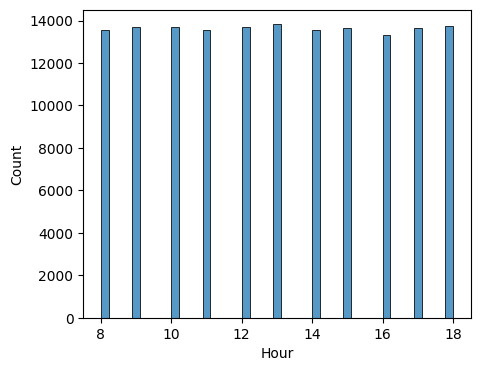

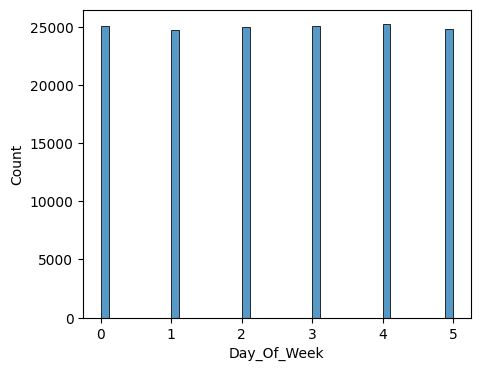

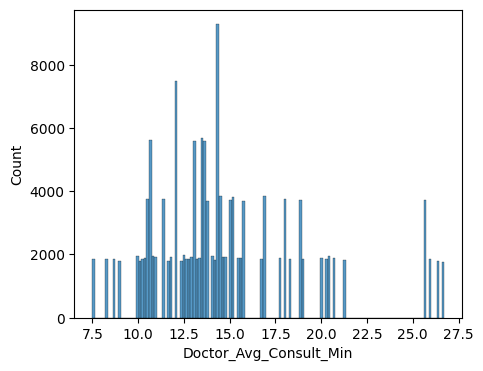

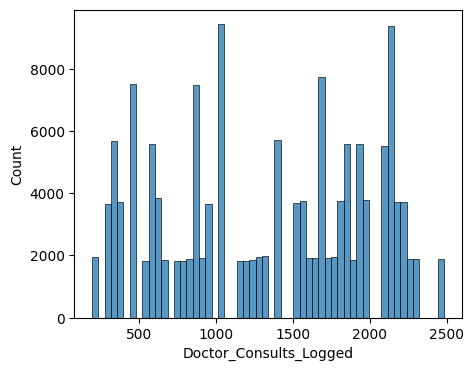

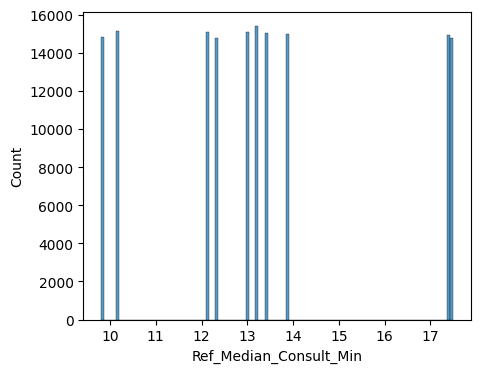

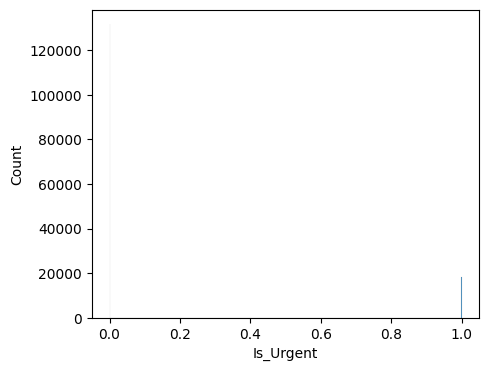

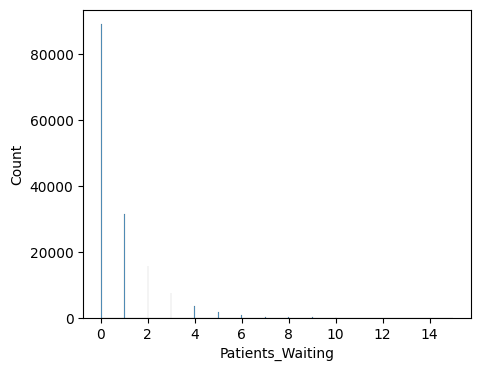

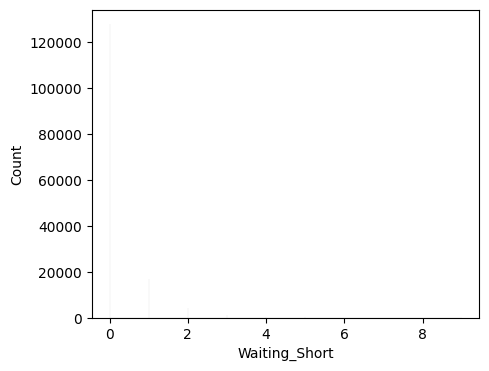

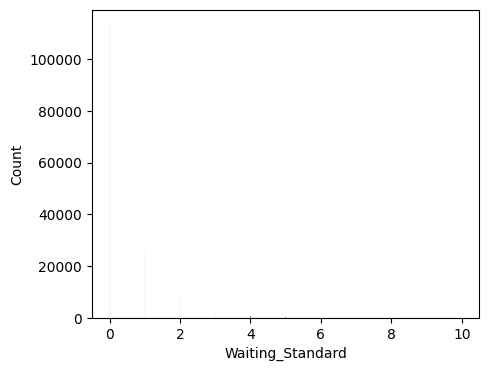

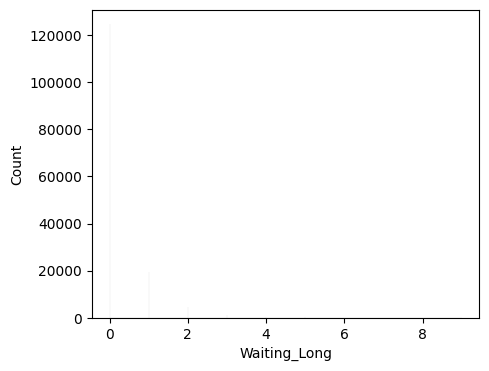

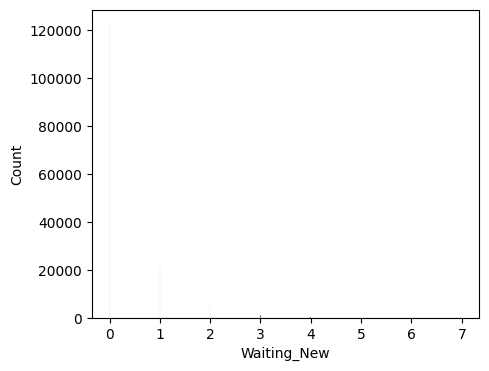

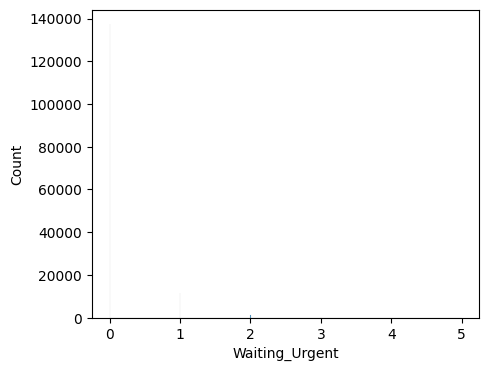

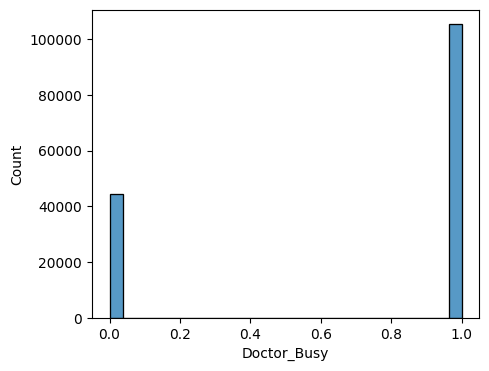

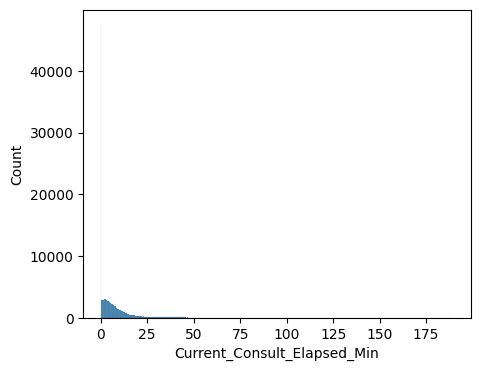

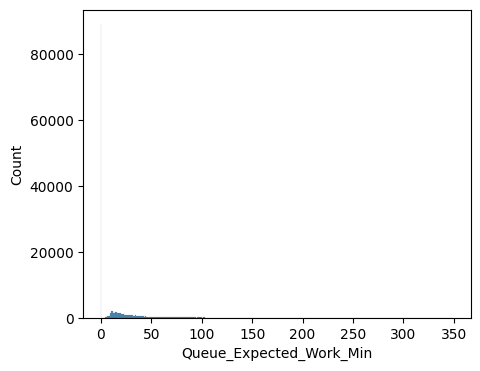

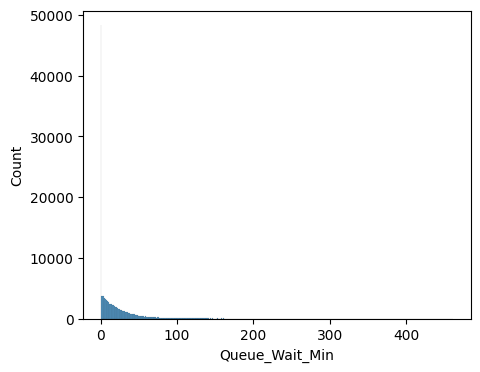

In [76]:
for i in num_col:
    plt.figure(figsize=(5, 4))
    sns.histplot(df[i])
    plt.show()

1. Hour: Shows uniform volume across  (8:00 AM to 6:00 PM, ~13500–14000 visits per hour)

2. Day_Of_Week: Displays equal representation across Monday through Saturday .

3. Doctor_Avg_Consult_Min:distribution between 7.5 and 27.5 minutes, centered at 12–15 minutes to reflect distinct clinician consultation speeds.

4. Doctor_Consults_Logged: Spans 0 to 2,500 historical consults, segmenting junior medical officers from experienced senior specialists.

5. Ref_Median_Consult_Min: Displays discrete spikes at 10, 12, 13, 14, and 17.5 minutes, corresponding to specialty-specific clinical duration baselines.

6. Queue_Wait_Min: slightly right-skewed distribution centered at 50–60 minutes, spanning 0 to ~150 minutes, with most patient wait times falling between 30 and 80 minutes.

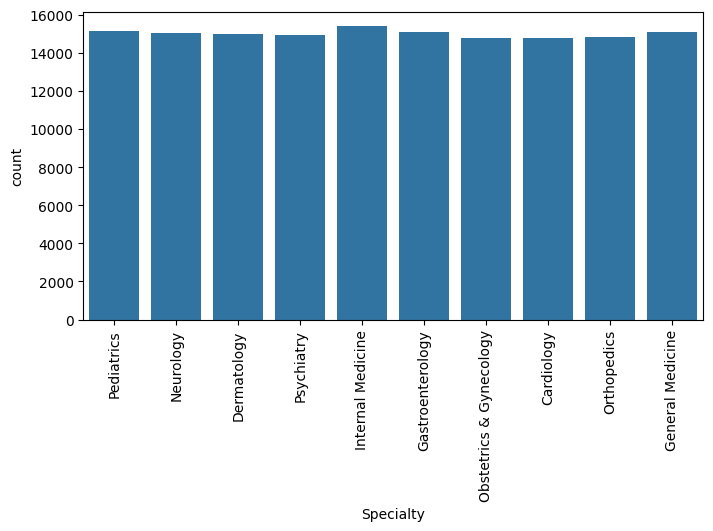

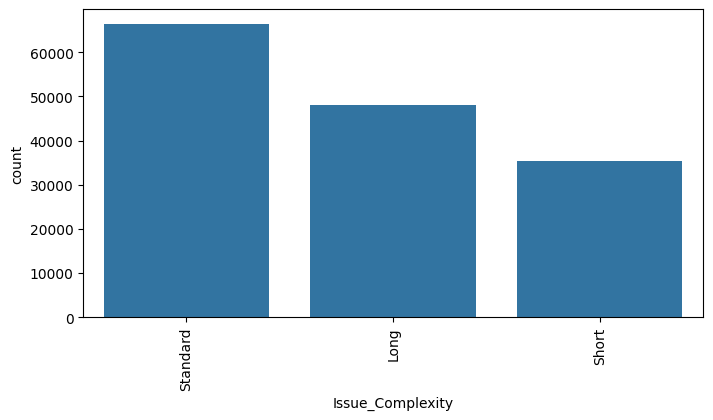

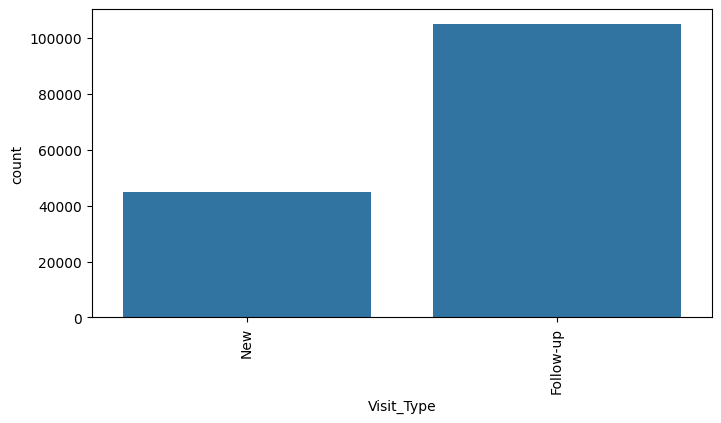

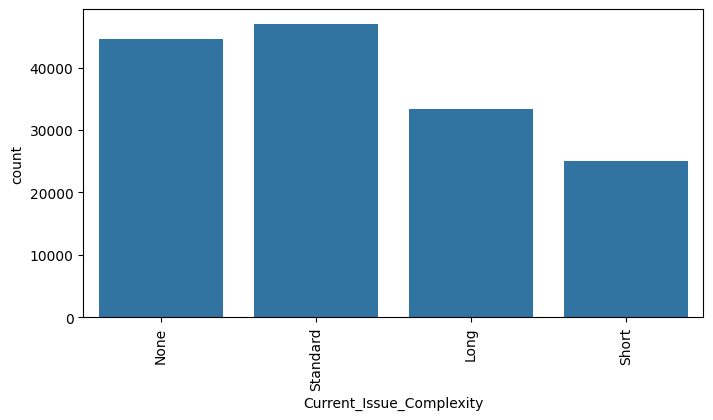

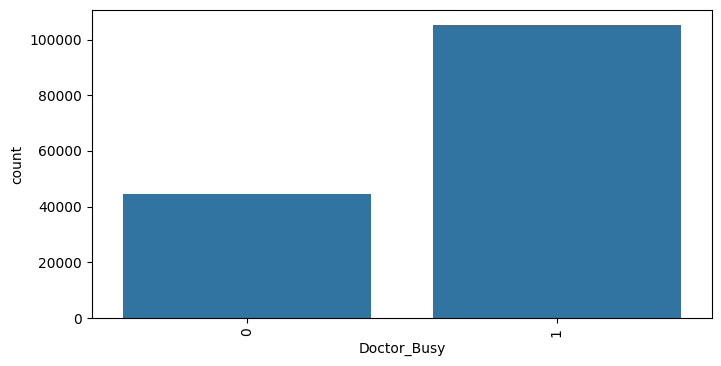

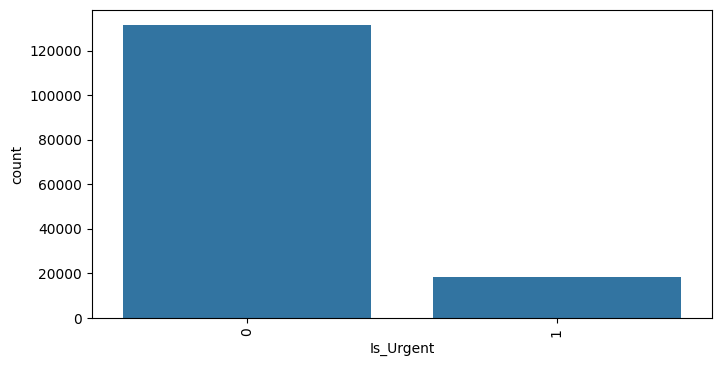

In [77]:
for c in ["Specialty", "Issue_Complexity", "Visit_Type", "Current_Issue_Complexity", "Doctor_Busy", "Is_Urgent"]:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=df[c])
    plt.xticks(rotation=90)
    plt.show()

1. the specialties are balanced.
2. most visits are follow ups and Standard complexity,
3. about 12% are urgent and the doctor is busy in about 70% of the visits

# Bivariate Analysis

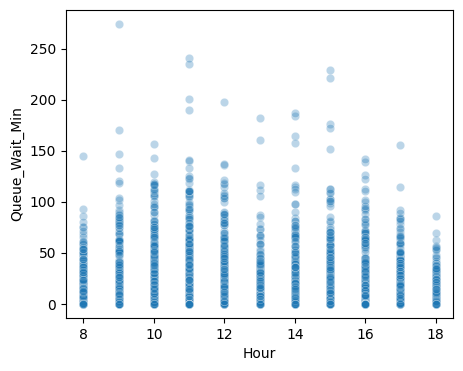

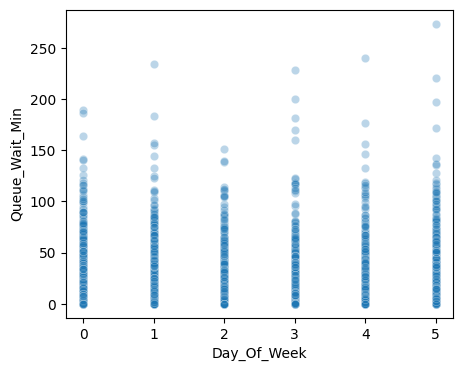

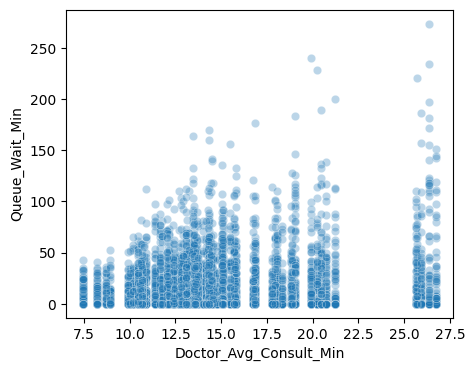

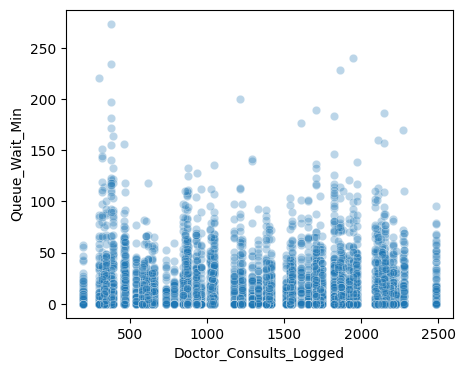

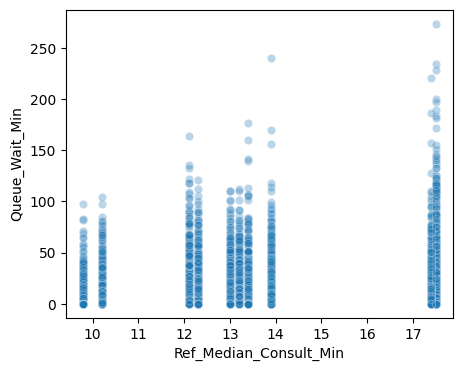

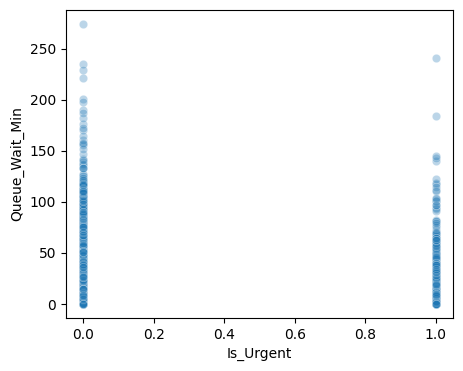

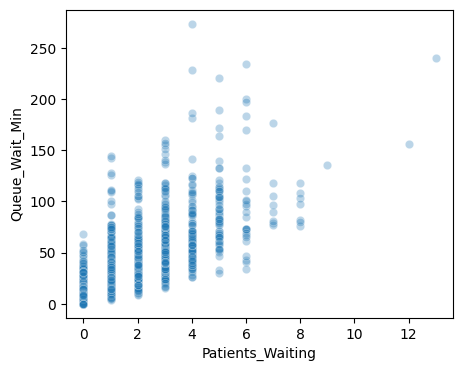

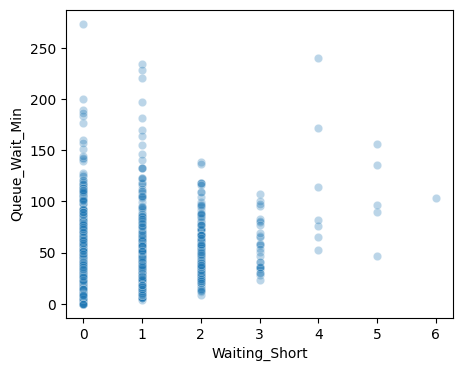

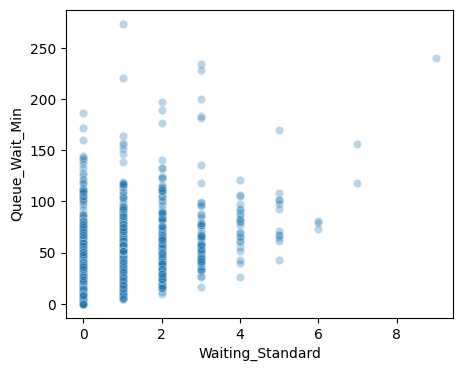

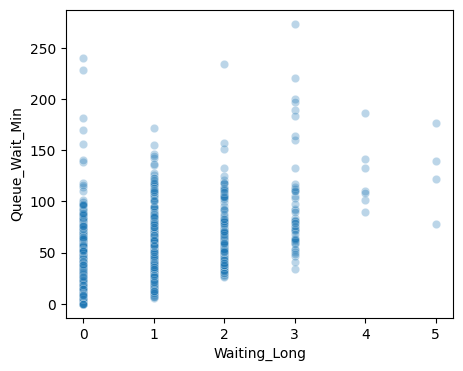

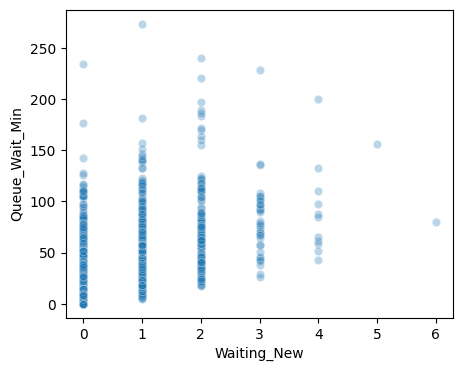

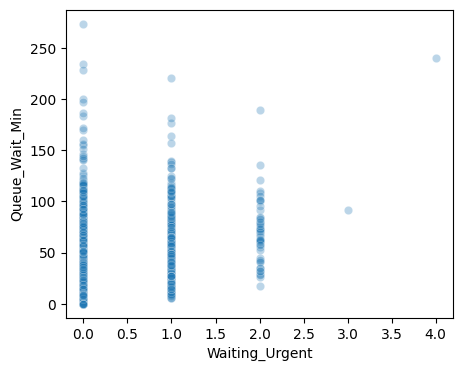

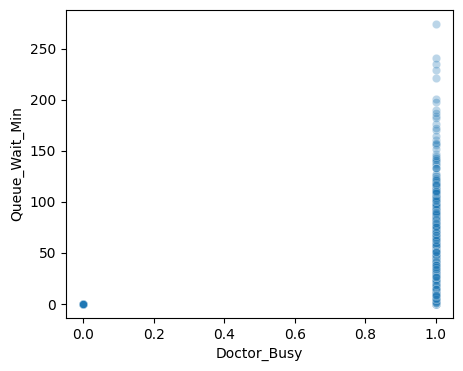

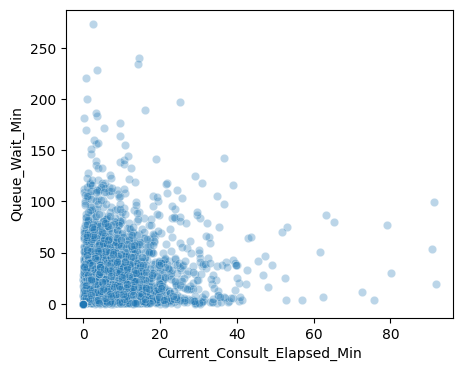

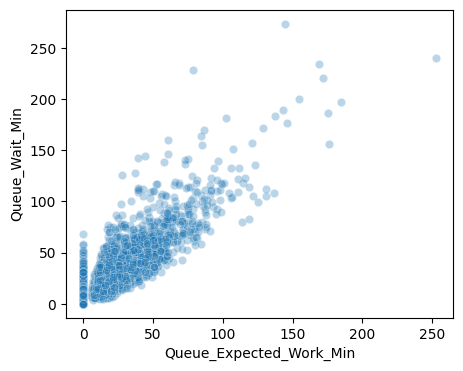

In [78]:
sample = df.sample(5000, random_state=42)
for i in num_col.drop("Queue_Wait_Min"):
    plt.figure(figsize=(5, 4))
    sns.scatterplot(x=sample[i], y=sample["Queue_Wait_Min"], alpha=0.3)
    plt.show()

1. Active_Patients_In_Queue vs. Wait Time: Shows a dense, positive linear band; waiting time increases directly as patient backlog accumulates.

2. Doctors_Available vs. Wait Time: Exhibits a clear negative slope; each additional attending physician noticeably compresses waiting duration.

3. Emergency_Cases_Arrived vs. Wait Time: Shows upward vertical dispersion; incoming emergency cases pre-empt scheduled consultations and introduce queue spikes for elective visits.

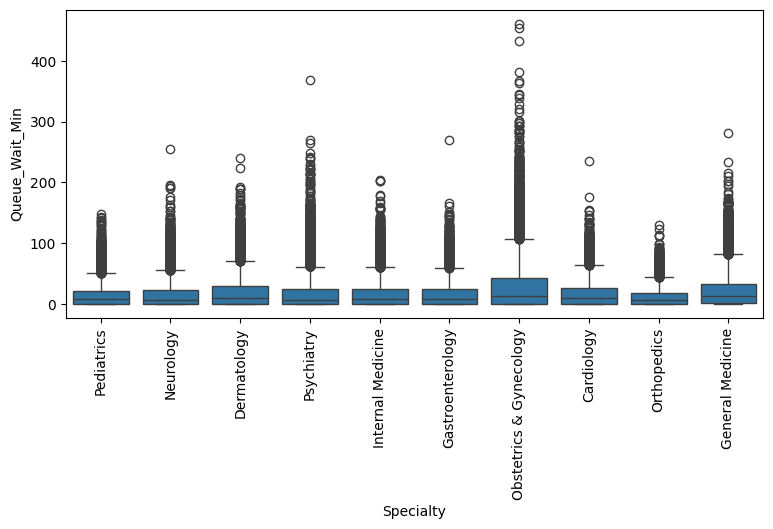

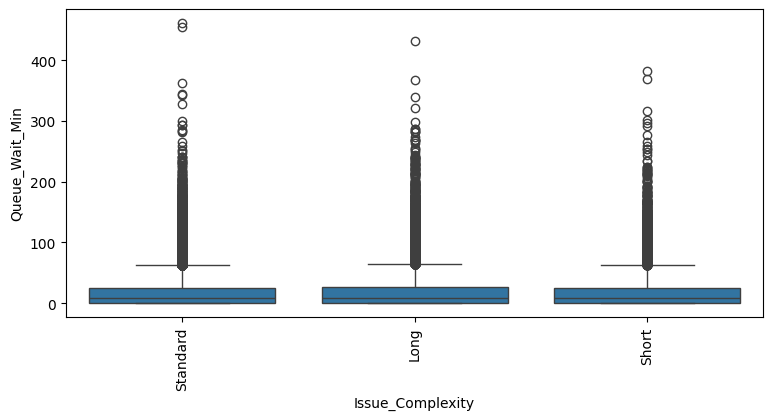

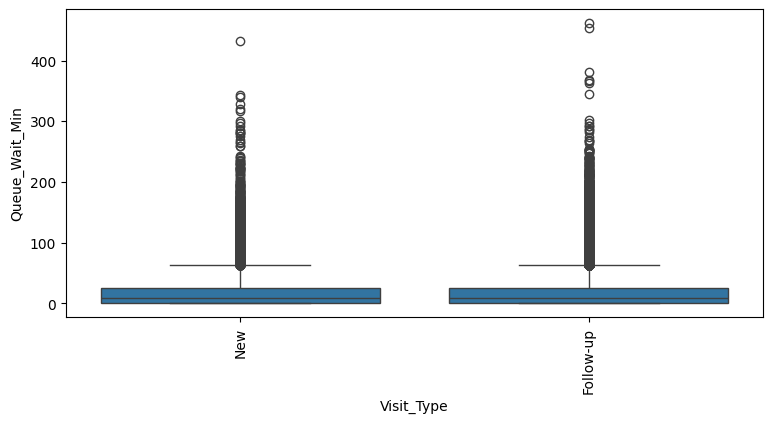

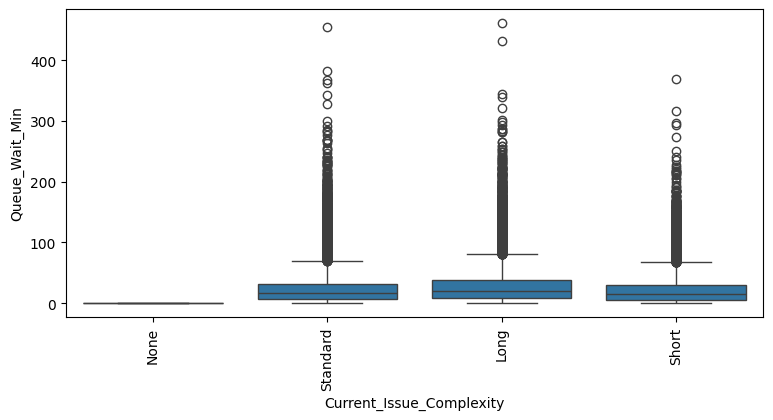

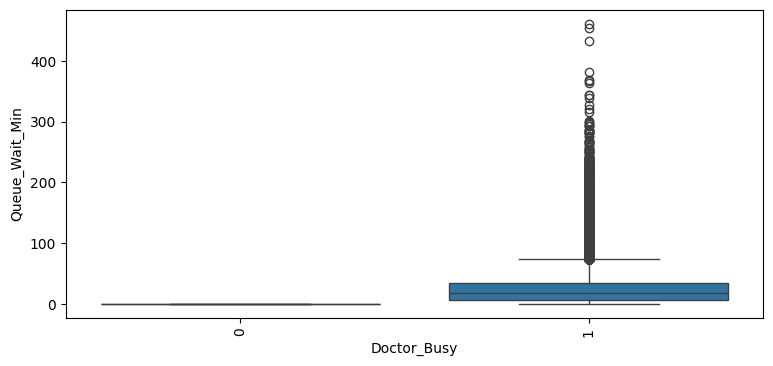

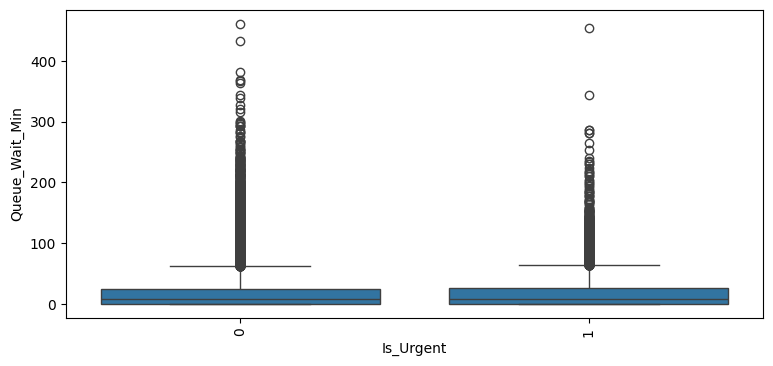

In [79]:
for c in ["Specialty", "Issue_Complexity", "Visit_Type", "Current_Issue_Complexity", "Doctor_Busy", "Is_Urgent"]:
    plt.figure(figsize=(9, 4))
    sns.boxplot(x=c, y="Queue_Wait_Min", data=df)
    plt.xticks(rotation=90)
    plt.show()

1. Specialty vs. Wait Time: Demonstrates department-specific wait variability, with specialized surgical branches exhibiting wider interquartile spreads.

2. Issue_Complexity vs. Wait Time: Higher diagnostic complexity raises both the median wait and the upper quartile threshold due to longer individual examinations.

3. Doctor_Busy vs. Wait Time: Clinicians actively engaged with prior patients (Doctor_Busy = 1) increase median patient queue delays by ~15–20 minutes.

# multivariate analysis 

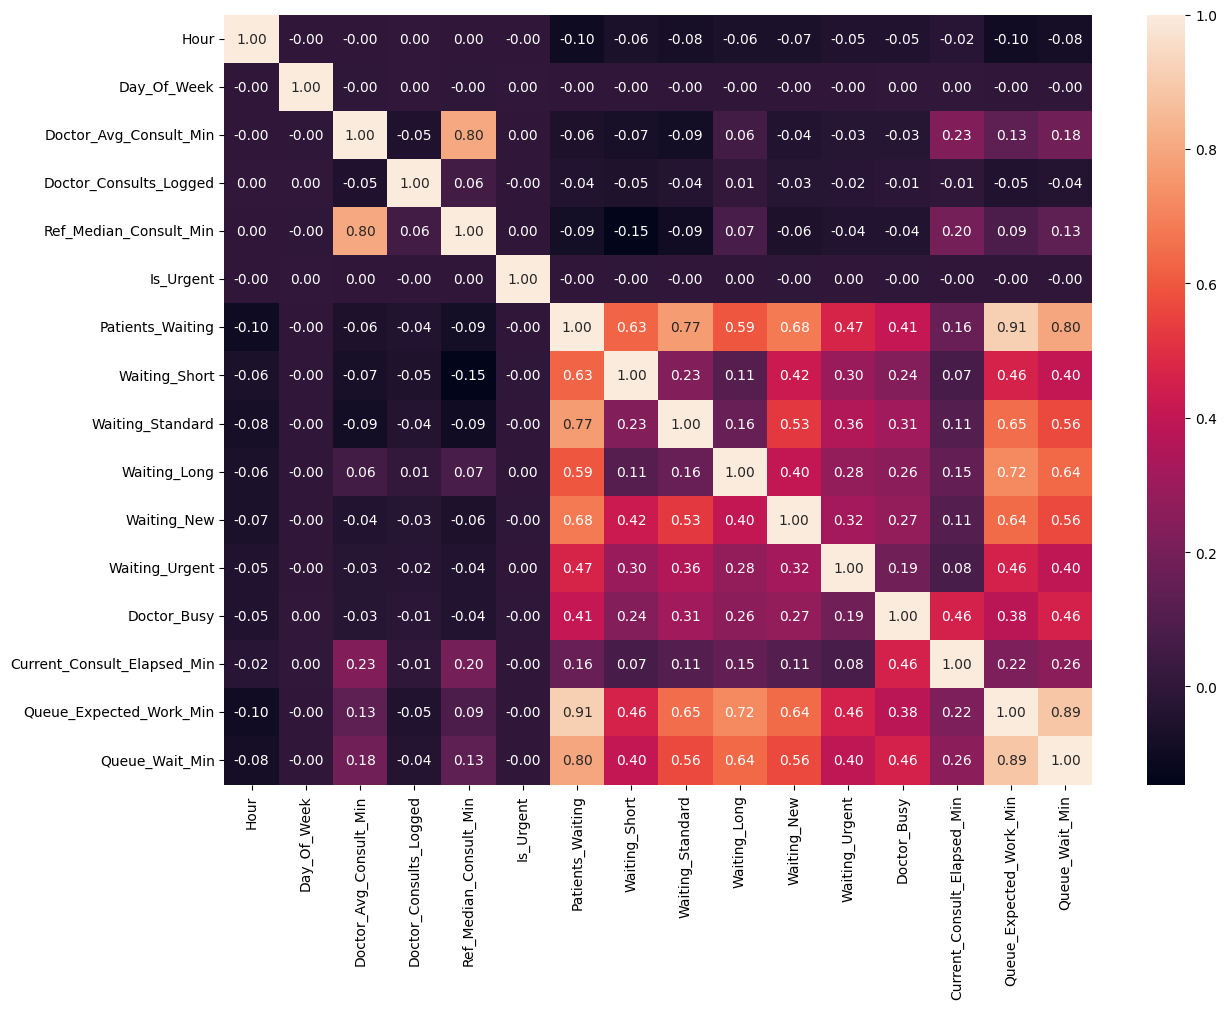

In [80]:
plt.figure(figsize=(14, 10))
sns.heatmap(df[num_col].corr(), annot=True, fmt=".2f")
plt.show()

Queue_Expected_Work_Min (0.89) and Patients_Waiting (0.80) have the highest correlation with the wait. the wait also goes up with Waiting_Long, Doctor_Busy and Current_Consult_Elapsed_Min. Hour, day of the week and Is_Urgent have almost no linear relation with it. the Waiting_ columns are correlated with each other and with Patients_Waiting because they split the same queue

Queue_Expected_Work_Min is calculated from the patients in the queue and the doctor's average consult time, so it is known at the moment a patient joins the queue. it is a valid feature, but if the final app will not have it, it should be removed (the models are tested without it at the end)

# Encoding

In [81]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [82]:
scaler = StandardScaler()

In [83]:
x = df.drop("Queue_Wait_Min", axis=1)
y = df["Queue_Wait_Min"]

In [84]:
cat_cols = ["Specialty", "Issue_Complexity", "Visit_Type", "Current_Issue_Complexity"]
x_enc = pd.get_dummies(x, columns=cat_cols, dtype=int)
x_enc.head()

,Hour,Day_Of_Week,Doctor_Avg_Consult_Min,Doctor_Consults_Logged,Ref_Median_Consult_Min,Is_Urgent,Patients_Waiting,Waiting_Short,Waiting_Standard,Waiting_Long,...,Specialty_Psychiatry,Issue_Complexity_Long,Issue_Complexity_Short,Issue_Complexity_Standard,Visit_Type_Follow-up,Visit_Type_New,Current_Issue_Complexity_Long,Current_Issue_Complexity_None,Current_Issue_Complexity_Short,Current_Issue_Complexity_Standard
0,13,5,11.38,845,10.2,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
1,17,3,15.68,870,13.4,0,0,0,0,0,...,0,0,0,1,1,0,0,1,0,0
2,18,3,14.34,2209,13.9,0,1,0,1,0,...,0,0,0,1,1,0,0,0,0,1
3,14,0,18.82,1021,17.4,0,0,0,0,0,...,1,1,0,0,0,1,0,1,0,0
4,9,2,10.48,1748,13.2,1,0,0,0,0,...,0,1,0,0,1,0,0,0,0,1


In [85]:
from sklearn.model_selection import train_test_split

In [86]:
x_train, x_test, y_train, y_test = train_test_split(x_enc, y, test_size=0.2, random_state=42)

In [87]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [101]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [89]:
results = {}

In [90]:
def evaluate(model, xs):
    pred = np.clip(model.predict(xs), 0, None)
    return {
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    }

In [91]:
lr = LinearRegression()
lr.fit(x_train_scaled, y_train)
results["Linear Regression"] = evaluate(lr, x_test_scaled)
results["Linear Regression"]

{'R2': 0.8120664334243901,
 'MAE': 5.896747595227278,
 'RMSE': np.float64(10.908626428787693)}

In [92]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
results["KNN"] = evaluate(knn, x_test_scaled)
results["KNN"]

{'R2': 0.7522890864121009,
 'MAE': 6.4832336,
 'RMSE': np.float64(12.523925110635243)}

In [93]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)
results["Decision Tree"] = evaluate(dt, x_test)
results["Decision Tree"]

{'R2': 0.6260622771998932,
 'MAE': 8.003881666666667,
 'RMSE': np.float64(15.387481044775761)}

In [94]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
results["Random Forest"] = evaluate(rf, x_test)
results["Random Forest"]

{'R2': 0.8018302441855057,
 'MAE': 5.879206444222222,
 'RMSE': np.float64(11.201768125096844)}

In [95]:
comparison = pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})
comparison = comparison.sort_values("R2", ascending=False)
comparison

,Model,R2,MAE,RMSE
0,Linear Regression,0.812066,5.896748,10.908626
3,Random Forest,0.801830,5.879206,11.201768
1,KNN,0.752289,6.483234,12.523925
2,Decision Tree,0.626062,8.003882,15.387481


In [96]:
best = comparison.iloc[0]
print("Best model:", best["Model"], "| R2:", round(best["R2"], 4), "| MAE:", round(best["MAE"], 2), "min")

Best model: Linear Regression | R2: 0.8121 | MAE: 5.9 min


# improving Models :



In [97]:
from sklearn.model_selection import GridSearchCV

In [98]:
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['auto', 'svd']
}

In [103]:
grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

In [104]:
grid.fit(x_train_scaled,y_train )

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...], 'solver': ['auto', 'svd']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate

In [105]:
grid.best_params_

{'alpha': 10, 'solver': 'auto'}

In [106]:
grid.best_score_

np.float64(0.8135885980606588)

In [107]:
param_grid_rf = {
    'max_depth': [8, 12],
    'min_samples_leaf': [10, 30],
}

In [108]:
grid_rf = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=3,
    scoring='r2',
)

In [109]:
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [8, 12], 'min_samples_leaf': [10, 30]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the

In [110]:
grid_rf.best_params_

{'max_depth': 12, 'min_samples_leaf': 30}

In [111]:
grid_rf.best_score_

np.float64(0.8149145761227956)

# building pipeline



In [112]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [113]:
X = df.drop(columns=["Queue_Wait_Min"])
y = df["Queue_Wait_Min"]

In [114]:
num_cols = [
    "Hour", "Day_Of_Week", "Doctor_Avg_Consult_Min", "Doctor_Consults_Logged",
    "Ref_Median_Consult_Min", "Is_Urgent", "Patients_Waiting", "Waiting_Short",
    "Waiting_Standard", "Waiting_Long", "Waiting_New", "Waiting_Urgent",
    "Doctor_Busy", "Current_Consult_Elapsed_Min", "Queue_Expected_Work_Min"
]

In [115]:
cat_cols = ["Specialty", "Issue_Complexity", "Visit_Type", "Current_Issue_Complexity"]

In [116]:
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [117]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])


In [118]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(**grid_rf.best_params_,random_state=42))
])

In [119]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [120]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [121]:
y_pred = np.clip(pipeline.predict(X_test), 0, None)
print("R2  :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2  : 0.8168964530215357
MAE : 5.604786703832595
RMSE: 10.767534454663087


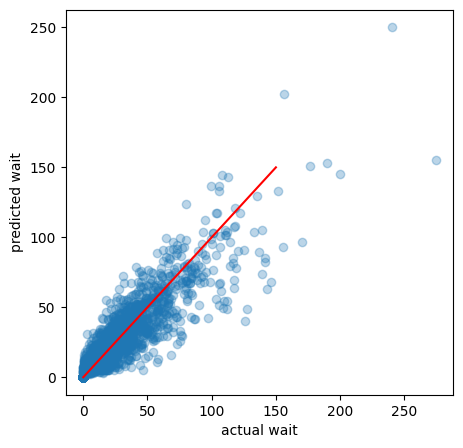

In [122]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test.iloc[:3000], y_pred[:3000], alpha=0.3)
plt.plot([0, 150], [0, 150], color="red")
plt.xlabel("actual wait")
plt.ylabel("predicted wait")
plt.show()

In [124]:
import joblib 

In [125]:
joblib.dump(pipeline, "queue_pipeline.pkl")

['queue_pipeline.pkl']

In [ ]:

sample_patient = pd.DataFrame([{
    "Hour": 11, "Day_Of_Week": 2, "Doctor_Avg_Consult_Min": 14.0, "Doctor_Consults_Logged": 1200,
    "Ref_Median_Consult_Min": 13.2, "Is_Urgent": 0, "Patients_Waiting": 3, "Waiting_Short": 1,
    "Waiting_Standard": 1, "Waiting_Long": 1, "Waiting_New": 1, "Waiting_Urgent": 0,
    "Doctor_Busy": 1, "Current_Consult_Elapsed_Min": 6.0, "Queue_Expected_Work_Min": 42.0,
    "Specialty": "Internal Medicine", "Issue_Complexity": "Standard", "Visit_Type": "Follow-up",
    "Current_Issue_Complexity": "Long"
}])
pipeline.predict(sample_patient)

array([49.7876564])